# Task 1: Data Preprocessing and Exploratory Data Analysis (EDA)

## Introduction

The goal of this project is to use machine learning to predict whether customers will cancel their subscriptions to a music streaming platform.

Before building machine learning models, we need to explore and prepare the dataset. This involves understanding the data, identifying missing or incorrect values, checking for outliers, and examining relationships between different features.

In this section, we will perform data preprocessing and exploratory data analysis (EDA) to better understand the dataset and prepare it for feature engineering and model training.

## 1.1 Import Libraries and Load Dataset

In [1]:
import pandas as pd

In [2]:
import os

os.listdir("datasets")

['test.csv', 'train.csv']

In [3]:
df = pd.read_csv("datasets/train.csv")

In [4]:
df.head()

,customer_id,age,location,subscription_type,payment_plan,num_subscription_pauses,payment_method,customer_service_inquiries,signup_date,weekly_hours,average_session_length,song_skip_rate,weekly_songs_played,weekly_unique_songs,num_favorite_artists,num_platform_friends,num_playlists_created,num_shared_playlists,notifications_clicked,churned
0,1,32,Montana,Free,Yearly,2,Paypal,Medium,-1606,22.391362,105.394516,0.176873,169,109,18,32,52,35,46,0
1,2,64,New Jersey,Free,Monthly,3,Paypal,Low,-2897,29.294210,52.501115,0.981811,55,163,44,33,12,25,37,1
2,3,51,Washington,Premium,Yearly,2,Credit Card,High,-348,15.400312,24.703696,0.048411,244,117,20,129,50,28,38,0
3,4,63,California,Family,Yearly,4,Apple Pay,Medium,-2894,22.842084,83.595480,0.035691,442,252,47,120,55,17,24,0
4,5,54,Washington,Family,Monthly,3,Paypal,High,-92,23.151163,52.578266,0.039738,243,230,41,66,40,32,47,0


The training dataset was loaded using pandas. I displayed the first five rows to get an initial look at the data and understand how the customer information is organized.

## 1.2 Dataset Overview

In this section, I will examine the dataset's size, column names, and data types. This will help me understand what information is available and identify which variables may need preprocessing.

In [5]:
df.shape

(125000, 20)

In [6]:
pd.DataFrame({
    "Column Number": range(1, len(df.columns) + 1),
    "Column Name": df.columns
})

,Column Number,Column Name
0,1,customer_id
1,2,age
2,3,location
3,4,subscription_type
4,5,payment_plan
5,6,num_subscription_pauses
6,7,payment_method
7,8,customer_service_inquiries
8,9,signup_date
9,10,weekly_hours


In [7]:
pd.DataFrame({
    "Column Name": df.columns,
    "Non-Null Count": df.notna().sum().values,
    "Data Type": df.dtypes.values
})

,Column Name,Non-Null Count,Data Type
0,customer_id,125000,int64
1,age,125000,int64
2,location,125000,str
3,subscription_type,125000,str
4,payment_plan,125000,str
5,num_subscription_pauses,125000,int64
6,payment_method,125000,str
7,customer_service_inquiries,125000,str
8,signup_date,125000,int64
9,weekly_hours,125000,float64


### Dataset Overview Findings

The training dataset contains 125,000 rows and 20 columns. The columns include both numerical and categorical data, such as customer age, subscription type, payment method, and listening activity.

Based on the data type summary, all 20 columns contain 125,000 non-null values, meaning there are no missing values detected so far. However, we still need to check for any incorrect or unrealistic values.

I also noticed that `signup_date` is stored as an integer instead of a date. This is something we will investigate during preprocessing. The `churned` column is our target variable, which represents whether a customer canceled their subscription.

## 1.3 Missing Values

In [8]:
df.isnull().sum()

customer_id                   0
age                           0
location                      0
subscription_type             0
payment_plan                  0
num_subscription_pauses       0
payment_method                0
customer_service_inquiries    0
signup_date                   0
weekly_hours                  0
average_session_length        0
song_skip_rate                0
weekly_songs_played           0
weekly_unique_songs           0
num_favorite_artists          0
num_platform_friends          0
num_playlists_created         0
num_shared_playlists          0
notifications_clicked         0
churned                       0
dtype: int64

### Missing Values Findings

I used `df.isnull().sum()` to check for missing values in each column. The results showed that all 20 columns have 0 missing values, meaning pandas did not detect any missing data in the training dataset.

Since no missing values were found, there is no need to fill or remove missing data at this stage. However, I will still check for incorrect or unrealistic values during the data-cleaning process.

In [9]:
df.duplicated().sum()

np.int64(0)

### Duplicate Rows Findings

I used `df.duplicated().sum()` to check whether the dataset contained any identical rows. The result was 0, meaning no duplicate rows were found.

Since there are no identical rows, I do not need to remove any duplicates at this stage.

In [10]:
df["customer_id"].duplicated().sum()

np.int64(0)

In [28]:
# Check for empty or whitespace-only text values
df.select_dtypes(include=["object", "str"]).apply(
    lambda col: col.str.strip().eq("").sum()
)

location                      0
subscription_type             0
payment_plan                  0
payment_method                0
customer_service_inquiries    0
dtype: int64

## 1.4 Data Types and Date Conversion

### Purpose

In this section, I will examine how the different variables are stored in the dataset and identify any columns that may need to be converted into a different data type.

I will also investigate the `signup_date` column to understand how the dates are represented before making any changes.

In [11]:
df["signup_date"].head(10)

0   -1606
1   -2897
2    -348
3   -2894
4     -92
5    -585
6   -1506
7    -703
8   -2311
9   -1635
Name: signup_date, dtype: int64

In [12]:
print("Minimum:", df["signup_date"].min())
print("Maximum:", df["signup_date"].max())

Minimum: -2922
Maximum: -1


### Findings

The `signup_date` column is stored as integers ranging from -2922 to -1. These values may represent the number of days before a reference date rather than actual calendar dates.

Since the date format has not been confirmed, I will leave this column unchanged for now.

## 1.5 Plausible Value Ranges and Outliers

We will examine the numerical features to identify unrealistic values, outliers, and possible data inconsistencies.

In [13]:
df.describe()

,customer_id,age,num_subscription_pauses,signup_date,weekly_hours,average_session_length,song_skip_rate,weekly_songs_played,weekly_unique_songs,num_favorite_artists,num_platform_friends,num_playlists_created,num_shared_playlists,notifications_clicked,churned
count,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000,125000.000000
mean,62500.500000,48.414136,1.991144,-1460.678936,25.036985,60.421725,0.500802,250.823928,150.783344,24.499888,99.713240,49.458048,24.554224,24.446848,0.513392
std,36084.536162,17.901042,1.417201,844.132871,14.447487,34.383782,0.288706,143.327606,85.794952,14.445979,57.681372,28.935305,14.454823,14.422850,0.499823
min,1.000000,18.000000,0.000000,-2922.000000,0.000068,1.000526,0.000006,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,31250.750000,33.000000,1.000000,-2190.000000,12.472667,30.644177,0.250974,127.000000,76.000000,12.000000,50.000000,24.000000,12.000000,12.000000,0.000000
50%,62500.500000,48.000000,2.000000,-1462.000000,25.116710,60.340977,0.501162,251.000000,150.000000,25.000000,100.000000,49.000000,25.000000,24.000000,1.000000
75%,93750.250000,64.000000,3.000000,-728.000000,37.570328,90.234158,0.751110,375.000000,225.000000,37.000000,150.000000,75.000000,37.000000,37.000000,1.000000
max,125000.000000,79.000000,4.000000,-1.000000,49.999943,119.996501,0.999970,499.000000,299.000000,49.000000,199.000000,99.000000,49.000000,49.000000,1.000000


In [14]:
(df["weekly_unique_songs"] > df["weekly_songs_played"]).sum()

np.int64(36996)

The numerical summary shows several values that need further investigation, particularly `average_session_length`, `num_subscription_pauses`, and the relationship between `weekly_songs_played` and `weekly_unique_songs`. I will check these inconsistencies before making any changes to the data.

In [16]:
invalid_songs = df[
    df["weekly_unique_songs"] > df["weekly_songs_played"]
]

invalid_songs[["weekly_songs_played", "weekly_unique_songs"]].head(10)

,weekly_songs_played,weekly_unique_songs
1,55,163
6,35,104
7,60,135
8,154,206
11,161,260
12,66,286
14,126,186
17,70,127
20,90,106
34,176,196


I found 36,996 records where `weekly_unique_songs` is greater than `weekly_songs_played`, which is approximately 29.6% of the dataset. This is inconsistent because the number of unique songs should not exceed the total songs played during the same period. These records need further investigation before deciding how to clean them.

In [21]:
df["average_session_length"].describe()

count    125000.000000
mean         60.421725
std          34.383782
min           1.000526
25%          30.644177
50%          60.340977
75%          90.234158
max         119.996501
Name: average_session_length, dtype: float64

The `average_session_length` values range from approximately 1 to 120, with a mean of 60.42. These values seem more realistic in minutes than hours, suggesting a possible error in the documented units. The values will remain unchanged until the units are confirmed.

In [22]:
df["num_subscription_pauses"].value_counts().sort_index()

num_subscription_pauses
0    25363
1    25036
2    24907
3    24733
4    24961
Name: count, dtype: int64

The `num_subscription_pauses` column contains values from 0 to 4, with a fairly even distribution. Although the documented maximum may be 2, values 3 and 4 appear frequently. I will keep these values unchanged until the expected range is confirmed.

## 1.6 Categorical Variables and Encoding

In this section, I will examine categorical variables, correct inconsistent values, and prepare them for machine learning.

In [18]:
df["location"].value_counts()

location
Georgia           6705
Idaho             6697
Vermont           6676
California        6665
Washington        6638
New Jersey        6634
Nebrasksa         6601
North Carolina    6583
Utah              6577
North Dakota      6577
New York          6574
Alabama           6555
Wisconsin         6553
Virginia          6541
South Carolina    6534
Maine             6523
West Virginia     6486
Florida           6480
Montana           6401
Name: count, dtype: int64

In [19]:
df_clean = df.copy()

df_clean["location"] = df_clean["location"].replace(
    "Nebrasksa", "Nebraska"
)

In [20]:
df_clean["location"].value_counts()

location
Georgia           6705
Idaho             6697
Vermont           6676
California        6665
Washington        6638
New Jersey        6634
Nebraska          6601
North Carolina    6583
Utah              6577
North Dakota      6577
New York          6574
Alabama           6555
Wisconsin         6553
Virginia          6541
South Carolina    6534
Maine             6523
West Virginia     6486
Florida           6480
Montana           6401
Name: count, dtype: int64

The `location` column contained 6,601 records where Nebraska was misspelled as `Nebrasksa`. I corrected the spelling to keep the state names consistent before categorical encoding.

In [25]:
df_clean.select_dtypes(include=["object", "str"]).columns

Index(['location', 'subscription_type', 'payment_plan', 'payment_method',
       'customer_service_inquiries'],
      dtype='str')

In [26]:
df_clean["subscription_type"].value_counts()

subscription_type
Premium    31354
Student    31305
Free       31269
Family     31072
Name: count, dtype: int64

categorical_cols = [
    "payment_plan",
    "payment_method",
    "customer_service_inquiries"
]

for col in categorical_cols:
    print(col)
    print(df_clean[col].value_counts())
    print()

The dataset contains five categorical columns. After correcting the Nebraska misspelling, the categories appear consistent, with no other obvious spelling issues. These variables will need appropriate encoding before training the machine learning models.

## 1.7 Target Class Distribution

In this section, I will examine the distribution of the `churned` variable to see whether the dataset contains a balanced number of customers who stayed and customers who canceled their subscriptions.

In [30]:
df_clean["churned"].value_counts()

churned
1    64174
0    60826
Name: count, dtype: int64

In [31]:
df_clean["churned"].value_counts(normalize=True) * 100

churned
1    51.3392
0    48.6608
Name: proportion, dtype: float64

The target variable is fairly balanced, with approximately 51.34% of customers classified as churned and 48.66% as active. Since both classes are similarly represented, there is no major class imbalance in the training dataset.

In [33]:
import matplotlib.pyplot as plt

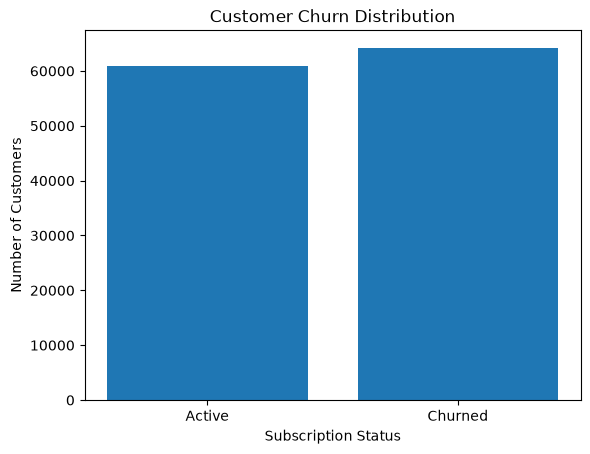

In [34]:
churn_counts = df_clean["churned"].value_counts().sort_index()

plt.bar(["Active", "Churned"], churn_counts)

plt.title("Customer Churn Distribution")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

plt.show()